# Data exploration: review and extensions

Companion to `exploration.ipynb`. We follow the same 13 sections, adding explanations, visualizations, and checks as we review each one. The original notebook remains the reference.

We will distinguish observations from preprocessing decisions and validate proposed changes before adopting them. All 13 sections of the original exploration have now been reviewed. Raw data is preserved; modeling and validated preprocessing remain separate work.


## 1. Load the data and identify the columns

Load the course CSVs, recover feature names, and check row alignment. `feature_names` holds column names; `y_raw` holds targets. Select the project's `.venv` kernel and start from the repository root or `notebooks/`.


In [ ]:
import csv
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

repo_root = Path.cwd().resolve()
if not (repo_root / "course_files").is_dir():
    repo_root = repo_root.parent
if not (repo_root / "course_files" / "helpers.py").is_file():
    raise FileNotFoundError("Start the notebook from the repository root or notebooks/.")

sys.path.insert(0, str(repo_root))
from course_files.helpers import load_csv_data

data_dir = repo_root / "data"


In [ ]:
def read_header(path):
    """Read the CSV column names without loading its observations."""
    with path.open(newline="") as source:
        return next(csv.reader(source))


train_header = read_header(data_dir / "x_train.csv")
test_header = read_header(data_dir / "x_test.csv")
target_header = read_header(data_dir / "y_train.csv")

# Both feature files must describe the same columns in the same order.
assert train_header == test_header, "Train/test feature names or ordering differ."

# The first CSV column holds row IDs, not a model feature.
feature_names = train_header[1:]
print(f"Found {len(feature_names)} features; target column: {target_header[1]}")


Found 321 features; target column: _MICHD


### Load and preserve the raw data

Use the unchanged course helper with all rows. Loading the full CSVs can take time and substantial memory. `X_train_raw` and `X_benchmark_raw` retain the original numeric survey codes and missing values; later sections should create separate processed arrays rather than overwrite them.


In [ ]:
X_train_raw, X_benchmark_raw, y_raw, train_ids, benchmark_ids = load_csv_data(data_dir)

# Read IDs from the target file: the helper only loads its label column.
target_ids = np.genfromtxt(
    data_dir / "y_train.csv", delimiter=",", skip_header=1, usecols=0, dtype=np.int64
)

# Each training respondent needs one target, and every column needs a name.
assert X_train_raw.shape == (y_raw.size, len(feature_names)), "Training dimensions differ."

# The competition benchmark must have the same features as the labeled data.
assert X_benchmark_raw.shape[1] == len(feature_names), "Benchmark feature count differs."

# Matching IDs in the same order ensure each target belongs to its feature row.
assert np.array_equal(train_ids, target_ids), "Feature rows and target IDs are misaligned."

# The course dataset uses -1 and 1 for its two target classes.
assert np.all(np.isin(y_raw, [-1, 1])), "Unexpected target labels."

print("All structure and alignment checks passed.")
print(f"Training features: {X_train_raw.shape}")
print(f"Benchmark features:     {X_benchmark_raw.shape}")
print(f"Training targets:  {y_raw.shape}")
print(f"Feature examples:  {feature_names[:10]}")


All structure and alignment checks passed.
Training features: (328135, 321)
Benchmark features:     (109379, 321)
Training targets:  (328135,)
Feature examples:  ['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM']


### Data splits and evaluation

The structure and alignment checks tell us what was loaded. They do not establish whether features are useful, correctly encoded, or free of target leakage.

**`x_test.csv` is the competition benchmark, not our local test set.** Its labels are hidden. All local training, validation, and test data must come from the labeled files (`x_train.csv` and `y_train.csv`). The current helper shuffles within each class using seed 42, keeping similar class proportions in all three sets.

| Data | Purpose |
| --- | --- |
| Local training | Fit models and preprocessing parameters. |
| Local validation | Choose features, hyperparameters, and classification thresholds. |
| Local test | Evaluate the selected pipeline once after model selection. |
| Competition benchmark | Generate predictions for AIcrowd; labels are hidden. |

If using cross-validation, reserve the local test set first, then create training/validation folds within the remaining development data. Fit learned preprocessing and feature selection only on each fold's training portion. Keep the local test set out of target-based exploration and tuning. Agree on split proportions with the validation workstream; record seeds and fold counts if adding shuffled cross-validation later.

After final local evaluation, refit the chosen pipeline on all labeled data before predicting the competition benchmark. Here, we use the benchmark only for structural checks and its row count.


### Using the shared splitter

`src/train_test_split.py` reuses the course CSV loader. It shuffles rows within each class using a fixed seed, then takes 60% of each class for training, 20% for validation, and the rest for local testing. Each set is shuffled again so its classes are mixed, with features, labels, and IDs kept aligned. This is a stratified random split, not a time-based split.

Usage example (not an automatically executed cell):

```python
from src.train_test_split import TrainTestSplit

splitter = TrainTestSplit(train_size=0.6, val_size=0.2, test_size=0.2, seed=42)
parts = splitter.split_csv(data_dir, output_dir=data_dir / "train_test_split")
X_train, y_train = parts["train"]["X"], parts["train"]["y"]
X_val, y_val = parts["val"]["X"], parts["val"]["y"]
X_test, y_test = parts["test"]["X"], parts["test"]["y"]
```

`data/train_test_split/` contains six CSVs: paired features and labels for train, validation, and test. Calling this again replaces those generated files. Train and validation sizes round down within each class; test receives the remaining rows. Stratification preserves the original class proportions; it does not make the dataset balanced. Use positive-class precision, recall, and F1 alongside accuracy when evaluating models. `data/train_test_split/x_test.csv` is our local test set; `data/x_test.csv` is the competition benchmark.

For already-loaded arrays, use `parts = splitter.split(X_train_raw, y_raw, train_ids)`. This does not save files. The descriptive exploration below still uses all labeled rows.

**Next: section 2 — review identifiers, survey metadata, and proposed feature exclusions.**


## 2. What do these fields mean?

**Goal:** understand these fields and record hypotheses about their usefulness. No exclusion decision is made here.

**How do we know?** The CSV header supplies the names. The [CDC codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf) supplies their definitions under **SAS Variable Name**, followed by **Description** and the meanings of response codes. We match the exact name; we do not infer its meaning from the abbreviation. The table below summarizes those definitions. Page numbers are the printed PDF pages; links jump to them.

| Field | Plain meaning | Page |
| --- | --- | --- |
| `_STATE` | Respondent's state/territory code. | [2–3](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=2) |
| `FMONTH` | Month assigned to the survey file. | [3](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=3) |
| `IDATE` | Full interview date. | [4](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=4) |
| `IMONTH`, `IDAY`, `IYEAR` | Interview month, day, and year, respectively. | [4–6](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=4) |
| `DISPCODE` | Whether the interview was complete or partial. | [6](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=6) |
| `SEQNO` | Interview sequence number within the year. | [6](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=6) |
| `_PSU` | Sampling-unit identifier; repeats `SEQNO`. | [6](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=6) |
| `_STSTR` | Code identifying the survey sampling stratum (group). | [100](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=100) |
| `_STRWT` | Weight correcting for sampling within that group. | [101](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=101) |
| `_RAWRAKE` | Weighting component based on household adults and phones. | [101](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=101) |
| `_WT2RAKE` | Product of `_STRWT` and `_RAWRAKE`. | [101](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=101) |
| `_DUALCOR` | Weighting adjustment for dual phone use. | [104](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=104) |
| `_LLCPWT` | Respondent's final population-representation weight. | [104](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=104) |
| `_CLLCPWT` | Corresponding final weight for the child survey. | [103](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=103) |
| `_CRACE1` | Child's race classification, allowing multiple races. | [102](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=102) |
| `_CPRACE` | Child's preferred race category. | [103](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=103) |
| `_CHISPNC` | Child's Hispanic-origin classification. | [102](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=102) |
| `NUMHHOL2` | Whether the household has multiple non-cell telephone numbers. | [23](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=23) |
| `NUMPHON2` | Number of those numbers used for residential purposes. | [24](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=24) |
| `CPDEMO1` | Whether the respondent has a personal cell phone. | [24](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=24) |
| `_DUALUSE` | Category describing combined landline/cell-phone use. | [103](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=103) |

**What can we conclude?** The definitions suggest questions to test, not a removal policy. These fields came from the original notebook's candidate list; we are reviewing that list rather than adopting its choices.

A survey weight describes how a sampled response represents the population. It is different from a model coefficient learned during training. `_DUALUSE` is a category, not a numeric weight.

The code below groups these names and reports which exist in our CSV. No columns are removed here.


In [ ]:
# Same metadata candidates as the original notebook, grouped for interpretation.
metadata_groups = {
    "Sequence fields": ["SEQNO", "_PSU"],
    "Interview metadata": ["FMONTH", "IDATE", "IMONTH", "IDAY", "IYEAR", "DISPCODE"],
    "Survey design and weights": [
        "_WT2RAKE", "_STSTR", "_STRWT", "_RAWRAKE", "_DUALCOR", "_LLCPWT", "_CLLCPWT"
    ],
    "Child demographics": ["_CRACE1", "_CPRACE", "_CHISPNC"],
    "Telephone questions": ["NUMHHOL2", "NUMPHON2", "CPDEMO1", "_DUALUSE"],
    "Geography": ["_STATE"],
}
for group, names in metadata_groups.items():
    print(f"{group}: {', '.join(names)}")
    missing_names = [name for name in names if name not in feature_names]
    if missing_names:
        print("  Not found in the CSV:", missing_names)


Sequence fields: SEQNO, _PSU
Interview metadata: FMONTH, IDATE, IMONTH, IDAY, IYEAR, DISPCODE
Survey design and weights: _WT2RAKE, _STSTR, _STRWT, _RAWRAKE, _DUALCOR, _LLCPWT, _CLLCPWT
Child demographics: _CRACE1, _CPRACE, _CHISPNC
Telephone questions: NUMHHOL2, NUMPHON2, CPDEMO1, _DUALUSE
Geography: _STATE


### Reasons to investigate exclusions — decisions remain open

| Group | Why might we exclude it? | What remains uncertain? |
| --- | --- | --- |
| Sequence fields | Record numbering may capture collection order rather than a transferable relationship. These are strong exclusion candidates. | Check their role and duplication before deciding. |
| Interview metadata | Collection timing or completeness could capture patterns that do not generalize. | It may still provide useful information. |
| Survey design and weights | Designed for survey estimation rather than as direct health measurements. | They may contain predictive information; using weights to weight training examples is a separate question. |
| Child demographics | Describes a child rather than directly describing the adult target. | Household information might still help prediction. |
| Telephone questions | May mainly reflect survey collection or household circumstances. | Such circumstances could be predictive. |
| Geography | Numeric state codes have no meaningful numerical order. | Appropriate categorical encoding may make geography useful. |

**Decision for now: retain every raw column.** Later, compare versions with and without each group using the same local validation splits and otherwise identical preprocessing and model settings. Keep the local test set and competition benchmark out of these choices.

This section documents meanings and hypotheses only. It does not establish that any group should be excluded.


## 3. Constant and nearly constant features

**Question:** which columns give almost everyone the same observed answer?

The original notebook ignores `NaN`, finds the most common remaining value, and flags columns where it represents at least **99% of observed responses**. We keep that calculation, but also show how many responses are present and how many are missing.

For example, 10 responses equal to 1 and 990 missing responses produce **100% dominance among observed responses**, but only **1% of all rows** contain that value. Missingness could still be informative.

We distinguish:

- **Entirely missing:** no observed values; dominance is undefined.
- **Constant among observed:** exactly one distinct observed value.
- **Nearly constant among observed:** more than one distinct observed value, with dominant share at least 99%.

The cutoff is a screening choice, not evidence that a feature is useless. Rare responses may still matter for the minority target class. These are raw survey codes; we will revisit the summaries after interpreting special response codes.

**Scope:** this first descriptive screen uses the full labeled feature matrix, without targets or the competition benchmark. No columns are selected or removed. Once local splits are available, recompute these statistics on local training data only before making feature-selection decisions; within cross-validation, recompute them for each training fold.


In [ ]:
# Like the original: find the most common observed value in each column.
# Keep counts too, so sparse columns do not look misleadingly constant.
n_rows, n_features = X_train_raw.shape
dominance_threshold = 0.99
observed_counts = np.zeros(n_features, dtype=int)
distinct_counts = np.zeros(n_features, dtype=int)
dominant_counts = np.zeros(n_features, dtype=int)
dominant_values = np.full(n_features, np.nan)

for i in range(n_features):
    column = X_train_raw[:, i]
    observed = column[~np.isnan(column)]
    observed_counts[i] = observed.size
    values, counts = np.unique(observed, return_counts=True)
    distinct_counts[i] = values.size
    if observed.size:
        most_common = np.argmax(counts)
        dominant_values[i] = values[most_common]
        dominant_counts[i] = counts[most_common]

# No observed responses means dominance is undefined, not 100%.
dominant_shares = np.divide(
    dominant_counts, observed_counts,
    out=np.full(n_features, np.nan), where=observed_counts > 0,
)
missing_pct = 100 * (n_rows - observed_counts) / n_rows
flagged_columns = np.flatnonzero(
    (dominant_shares >= dominance_threshold) | (observed_counts == 0)
)
print(f"Flagged {flagged_columns.size} of {n_features} columns at {dominance_threshold:.0%}.")


Flagged 10 of 321 columns at 99%.


In [ ]:
# Dominance uses observed rows; missingness uses all labeled rows.
print(f"{'Feature':<16} {'Most common':>12} {'Observed':>10} {'Distinct':>9} "
      f"{'Dom./observed':>14} {'Missing/all':>12}  Status")
for i in flagged_columns:
    status = ("entirely missing" if observed_counts[i] == 0 else
              "constant among observed" if distinct_counts[i] == 1 else
              "nearly constant among observed")
    value = "n/a" if observed_counts[i] == 0 else f"{dominant_values[i]:g}"
    share = "n/a" if observed_counts[i] == 0 else f"{dominant_shares[i]:.2%}"
    print(f"{feature_names[i]:<16} {value:>12} {observed_counts[i]:>10,} "
          f"{distinct_counts[i]:>9} {share:>14} {missing_pct[i]:>11.2f}%  {status}")


Feature           Most common   Observed  Distinct  Dom./observed  Missing/all  Status
CTELENUM                    1    188,720         1        100.00%       42.49%  constant among observed
PVTRESD1                    1    188,720         2         99.98%       42.49%  nearly constant among observed
COLGHOUS                    1         32         1        100.00%       99.99%  constant among observed
STATERES                    1    188,719         1        100.00%       42.49%  constant among observed
CTELNUM1                    1    139,415         1        100.00%       57.51%  constant among observed
CELLFON2                    1    139,415         1        100.00%       57.51%  constant among observed
PVTRESD2                    1    139,415         2         99.42%       57.51%  nearly constant among observed
CCLGHOUS                    1        801         1        100.00%       99.76%  constant among observed
_FRT16                      1    328,135         2         99.98%  

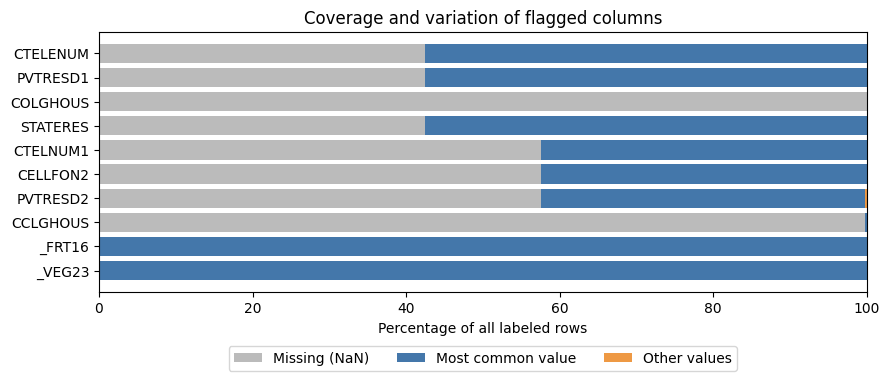

In [ ]:
# All segments use all rows as the denominator. Show at most 20 flagged columns.
indices = flagged_columns[:20]
if indices.size:
    missing = missing_pct[indices]
    common = 100 * dominant_counts[indices] / n_rows
    other = 100 * (observed_counts[indices] - dominant_counts[indices]) / n_rows
    names = [feature_names[i] for i in indices]
    fig, ax = plt.subplots(figsize=(9, max(3, 0.4 * indices.size)))
    ax.barh(names, missing, label="Missing (NaN)", color="#BBBBBB")
    ax.barh(names, common, left=missing, label="Most common value", color="#4477AA")
    ax.barh(names, other, left=missing + common, label="Other values", color="#EE9944")
    ax.invert_yaxis()
    ax.set(xlim=(0, 100), xlabel="Percentage of all labeled rows",
           title="Coverage and variation of flagged columns")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
    fig.tight_layout()
    plt.show()
else:
    print("No columns flagged.")


### How to read the results

A mostly blue bar means most rows share the same observed value. A mostly gray bar means the dominance estimate rests on a small observed subset. A fully gray bar has no observed values. Orange shows the remaining observed responses, even when their share is small.

The table distinguishes these situations and records their support. Neither a 99% dominant share nor a high missing percentage automatically triggers removal. No data or feature names are modified.

### Findings from the saved run (328,135 labeled rows)

- **10 of 321 features** meet the screen: six constant among observed responses and four nearly constant. No column is entirely missing in this run.
- `COLGHOUS` has only **32 observed responses** (99.99% missing), and `CCLGHOUS` has **801** (99.76% missing). Their 100% observed dominance says little about the full population of rows.
- `CELLFON2`, `CTELNUM1`, `CTELENUM`, and `STATERES` also have one observed value, but much larger observed subsets. If we fill their missing entries with that same value, the resulting feature becomes entirely constant; a separate missingness indicator could preserve the observed/missing distinction.
- `_VEG23` and `_FRT16` are **fully observed**, with dominant shares of 99.99% and 99.98%. Their limited variation is not caused by `NaN`s. The meaning and usefulness of their rare codes still need investigation.
- Several features share missingness percentages around 42.49% or 57.51%. This suggests a possible shared survey route or collection mechanism; equal percentages alone do not establish that the same respondents are missing.

**Conclusion:** these features have limited observed variation, sparse coverage, or both. We have not established whether they improve prediction. Keep them intact and revisit their response codes and missingness before testing exclusions on local validation data.


## 4. Missingness across all features

**Question:** how much information is actually observed in each column?

The original notebook counts `NaN`s and lists columns with **more than 90% missing values**. We keep that strict cutoff as a review flag, and add the overall distribution plus a closer look at the 20 sparsest columns, including their observed counts.

**What counts as missing here?** Only literal `NaN`. Numeric survey codes have not yet been interpreted, so a recorded value may still mean an unknown or refused answer. These results describe raw missingness, not a complete measure of usable information.

We reuse section 3's counts rather than scan the full matrix again. The same scope applies: all labeled feature rows, no targets or benchmark, and no learned selection rule. Any eventual removal or imputation rule must be fitted within the local training split (or each training fold).


In [ ]:
# Same strict >90% NaN criterion as the original; no removal is applied.
missingness_threshold = 90
high_missing_columns = np.flatnonzero(missing_pct > missingness_threshold)
missing_order = np.argsort(-missing_pct, kind="stable")
print(f"Features reviewed: {n_features}")
print(f"No raw NaNs: {np.count_nonzero(missing_pct == 0)}")
print(f"Some raw NaNs: {np.count_nonzero(missing_pct > 0)}")
print(f"More than 90% missing: {high_missing_columns.size}")
print(f"Entirely missing: {np.count_nonzero(observed_counts == 0)}")
print(f"Median missing percentage across columns: {np.median(missing_pct):.2f}%")


Features reviewed: 321
No raw NaNs: 82
Some raw NaNs: 239
More than 90% missing: 99
Entirely missing: 0
Median missing percentage across columns: 35.76%


In [ ]:
print(f"{'Feature':<18} {'Observed rows':>15} {'Missing rows':>15} {'Missing/all':>13}")
for i in missing_order:
    if missing_pct[i] > missingness_threshold:
        print(f"{feature_names[i]:<18} {observed_counts[i]:>15,} "
              f"{n_rows - observed_counts[i]:>15,} {missing_pct[i]:>12.2f}%")


Feature              Observed rows    Missing rows   Missing/all
COLGHOUS                        32         328,103        99.99%
LADULT                          32         328,103        99.99%
PCDMDECN                       179         327,956        99.95%
ASERVIST                       228         327,907        99.93%
ASDRVIST                       228         327,907        99.93%
ASNOSLEP                       342         327,793        99.90%
ASTHMED3                       485         327,650        99.85%
ASINHALR                       485         327,650        99.85%
ASYMPTOM                       486         327,649        99.85%
ASRCHKUP                       487         327,648        99.85%
ASACTLIM                       487         327,648        99.85%
ASATTACK                       490         327,645        99.85%
STREHAB1                       517         327,618        99.84%
PCPSADE1                       596         327,539        99.82%
HAREHAB1                 

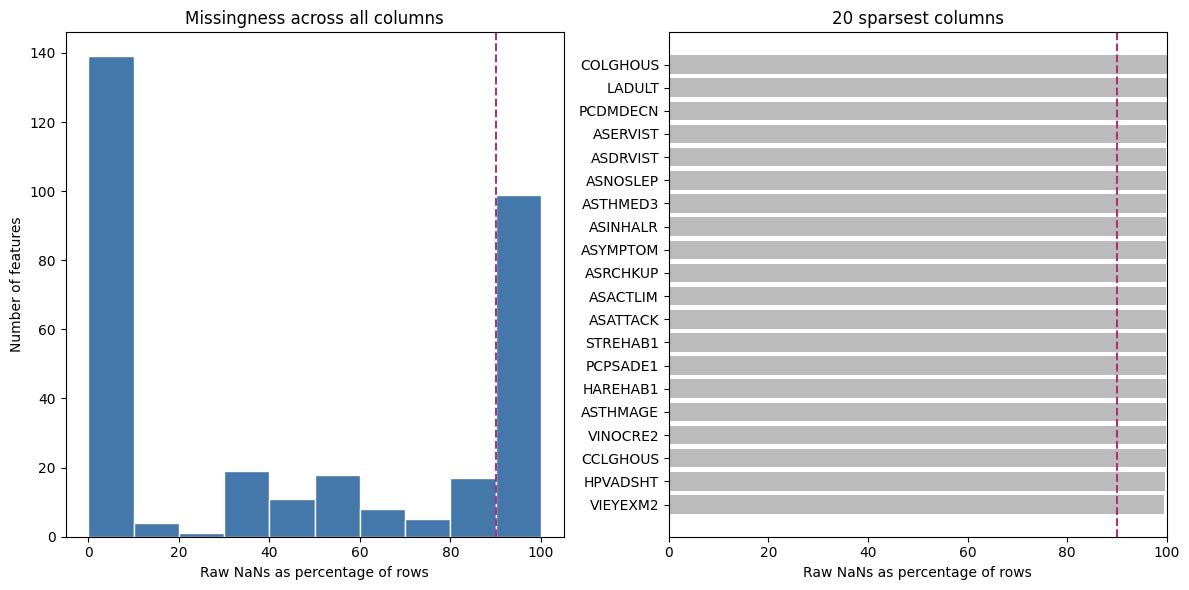

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].hist(missing_pct, bins=np.linspace(0, 100, 11), color="#4477AA", edgecolor="white")
axes[0].axvline(missingness_threshold, color="#AA3377", linestyle="--")
axes[0].set(xlabel="Raw NaNs as percentage of rows", ylabel="Number of features",
            title="Missingness across all columns")

indices = missing_order[:20]
axes[1].barh([feature_names[i] for i in indices], missing_pct[indices], color="#BBBBBB")
axes[1].invert_yaxis()
axes[1].axvline(missingness_threshold, color="#AA3377", linestyle="--")
axes[1].set(xlim=(0, 100), xlabel="Raw NaNs as percentage of rows", title="20 sparsest columns")
fig.tight_layout()
plt.show()


### What these results can and cannot tell us

The histogram shows how widespread raw missingness is. The ranking and table show which columns have the least observed support. For example, 95% missing means only 5% of rows provide an observed code, not that the column is necessarily useless.

Missing values could arise from skipped questions, survey modules, or nonresponse. We need the codebook and later pattern checks to distinguish these explanations; the percentages alone cannot identify the cause. Sparse columns may also describe a particular subgroup rather than a random sample of respondents.

**Decision:** retain all columns. Record sparse features for investigation, decode special response values later, and compare missing-value handling strategies through local validation. No imputation or feature removal is performed here.

### Findings from the saved run (328,135 labeled rows)

- **239 of 321 columns** contain raw `NaN`s; only **82** have none. Missingness is widespread rather than confined to a few fields.
- **99 columns** have more than 90% missing values, but **none** is entirely missing. Each has at least some observed responses; the amount varies greatly.
- The **median missing percentage across columns is 35.76%**. This describes the middle column's missingness, not the percentage missing across all cells or for a typical respondent.
- `COLGHOUS` and `LADULT` have only **32** observed responses each; `PCDMDECN` has **179**. Analyses of their observed values would rely on very small subsets.
- At the other end of the flagged group, `WTCHSALT` has **30,617** observed responses despite 90.67% missingness. A percentage alone hides the absolute support available.
- Several groups have similar observed counts: for example, `INSULIN`, `BLDSUGAR`, and related columns have around **21,700**, while several `AD...` columns have around **15,100**. Shared survey modules or routing are possible explanations, not established causes. Similar counts do not prove the same rows are observed.

**Conclusion:** missing-value handling will be an important modeling choice. Before trying imputation, missingness indicators, or exclusions, check response-code meanings and survey routing. Having no raw `NaN`s does not guarantee complete usable information: numeric codes can still represent missing responses. No columns are removed, and these summaries do not establish predictive usefulness.


## 5. Correlations and potentially redundant features

**Question:** do some features measure almost the same thing?

The original notebook computes pairwise Pearson correlations, ignoring rows where either feature is `NaN`, and flags **absolute correlation at least 0.95**. It accepts as few as two shared observations. Two varying observations always yield a perfect positive or negative correlation, so an impressive coefficient can rest on almost no evidence.

We improve this in two ways:

- Report the number and percentage of rows supporting each coefficient. For this descriptive screen, require at least **1,000 shared observations and 1% of labeled rows**. This is a review setting, not a guarantee of reliability.
- Start with a **documented numerical subset**, rather than applying Pearson correlation to arbitrary category codes. Category association needs a different analysis later. This first pass covers five measurements, not all 321 features.

Pearson correlation describes linear association: near +1 means the two measurements tend to increase together; near -1 means one tends to decrease as the other increases; near zero means little linear association in the observed subset. None of these establishes causation, target relevance, or a removal decision.

### Which numerical fields, and how do we know?

Definitions and encodings come from the [CDC codebook, printed pages 113–115](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=113).

| Field | Interpretation in this section | Course CSV representation used here |
| --- | --- | --- |
| `_AGE80` | Imputed age, capped at 80 years | Use recorded years. |
| `HTIN4` | Height in inches | Keep recorded units. |
| `HTM4` | Height in meters | Already in meters; keep as supplied. |
| `WTKG3` | Weight in kilograms | Already in kg; blanks load as NaN. |
| `_BMI5` | Body mass index | Already in BMI units; blanks load as NaN. |

**Check the actual CSV as well as the codebook.** The codebook describes the original survey encoding; the course CSV has already applied the implied decimal places. Its first row contains `HTM4=1.55`, `WTKG3=49.9`, and `_BMI5=20.78`. We must not divide these by 100 again. Blanks are already loaded as NaN. Positive changes of scale do not change Pearson correlation, but incorrect units would make descriptive statistics misleading. Two height fields may be closely related because they represent the same measurement. Do not infer that from the coefficient alone: compare definitions and observed coverage too.

This remains descriptive analysis of labeled feature rows only. No target or benchmark is used. Any resulting selection must be evaluated within the local training/validation workflow.


In [ ]:
# Audit two examples from the original correlation output without interpreting
# their raw category codes as continuous measurements.
column_positions = {name: i for i, name in enumerate(feature_names)}
audit_pairs = [("SEQNO", "_PSU"), ("LADULT", "FEETCHK2")]
print("Shared raw observations for examples from the original notebook:")
for first, second in audit_pairs:
    if first not in column_positions or second not in column_positions:
        print(f"{first} / {second}: field not found")
        continue
    x = X_train_raw[:, column_positions[first]]
    y = X_train_raw[:, column_positions[second]]
    observed = np.isfinite(x) & np.isfinite(y)
    print(f"{first} / {second}: {observed.sum():,} rows ({observed.mean():.2%})")
    if (first, second) == ("SEQNO", "_PSU"):
        print("  Equal values and matching NaN positions:", np.array_equal(x, y, equal_nan=True))


Shared raw observations for examples from the original notebook:
SEQNO / _PSU: 328,135 rows (100.00%)
  Equal values and matching NaN positions: True
LADULT / FEETCHK2: 2 rows (0.00%)


In [ ]:
# Reviewed numerical subset: the course CSV already uses the final units.
numeric_names = ["_AGE80", "HTIN4", "HTM4", "WTKG3", "_BMI5"]
numeric_values = X_train_raw[:, [feature_names.index(name) for name in numeric_names]].copy()
print("Numerical fields reviewed:", numeric_names)
print("Units as supplied: years, inches, meters, kg, and BMI. No extra scaling.")


Numerical fields reviewed: ['_AGE80', 'HTIN4', 'HTM4', 'WTKG3', '_BMI5']
Units as supplied: years, inches, meters, kg, and BMI. No extra scaling.


In [ ]:
# Same pairwise correlation logic as the original, with a shared-row requirement.
min_shared = max(1000, int(np.ceil(0.01 * n_rows)))
correlation_threshold = 0.95
numeric_correlations = np.full((len(numeric_names), len(numeric_names)), np.nan)
shared_counts = np.zeros_like(numeric_correlations, dtype=int)

for i in range(len(numeric_names)):
    for j in range(i, len(numeric_names)):
        valid = np.isfinite(numeric_values[:, i]) & np.isfinite(numeric_values[:, j])
        shared_counts[i, j] = shared_counts[j, i] = valid.sum()
        if valid.sum() >= min_shared:
            x, y = numeric_values[valid, i], numeric_values[valid, j]
            if np.std(x) > 0 and np.std(y) > 0:
                r = np.corrcoef(x, y)[0, 1]
                numeric_correlations[i, j] = numeric_correlations[j, i] = r

print(f"Minimum shared observations: {min_shared:,}; n/a means unsupported or constant.")
print(f"{'Feature 1':<12} {'Feature 2':<12} {'Pearson r':>10} {'Shared rows':>13}  Review")
for i, first in enumerate(numeric_names):
    for j in range(i + 1, len(numeric_names)):
        r = numeric_correlations[i, j]
        value = "n/a" if np.isnan(r) else f"{r:.4f}"
        flag = "high correlation" if abs(r) >= correlation_threshold else ""
        print(f"{first:<12} {numeric_names[j]:<12} {value:>10} {shared_counts[i, j]:>13,}  {flag}")


Minimum shared observations: 3,282; n/a means unsupported or constant.
Feature 1    Feature 2     Pearson r   Shared rows  Review
_AGE80       HTIN4           -0.1356       315,414  
_AGE80       HTM4            -0.1331       316,767  
_AGE80       WTKG3           -0.0596       305,129  
_AGE80       _BMI5           -0.0024       301,062  
HTIN4        HTM4             0.9996       315,414  high correlation
HTIN4        WTKG3            0.4709       301,506  
HTIN4        _BMI5           -0.0004       299,799  
HTM4         WTKG3            0.4690       302,778  
HTM4         _BMI5           -0.0065       301,062  
WTKG3        _BMI5            0.8709       301,062  


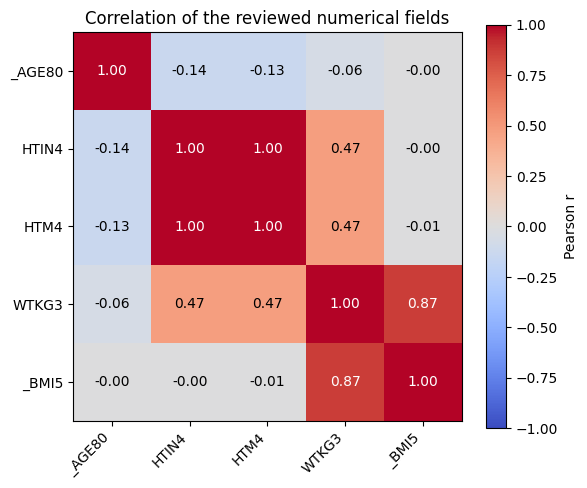

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(np.ma.masked_invalid(numeric_correlations), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(numeric_names)))
ax.set_yticks(range(len(numeric_names)))
ax.set_xticklabels(numeric_names, rotation=45, ha="right")
ax.set_yticklabels(numeric_names)
ax.set_title("Correlation of the reviewed numerical fields")
fig.colorbar(image, ax=ax, label="Pearson r")
for i in range(len(numeric_names)):
    for j in range(len(numeric_names)):
        r = numeric_correlations[i, j]
        ax.text(j, i, "n/a" if np.isnan(r) else f"{r:.2f}", ha="center", va="center",
                color="white" if abs(r) > 0.7 else "black")
fig.tight_layout()
plt.show()


### What we can conclude from this section

A supported high correlation identifies a pair worth investigating for overlapping information. It does not establish which feature to remove. Check definitions, missingness patterns, and whether the relationship changes outside the observed subset. A low Pearson correlation does not rule out nonlinear dependence; BMI, for example, is constructed from height and weight.

The sequence-field audit checks actual equality rather than relying on correlation to infer duplication. The sparse-pair audit shows why the original correlation table needs shared-observation counts.

This analysis deliberately leaves nominal survey categories and unreviewed numeric encodings out of the heatmap. Extend the numerical list only after checking definitions and response codes; do not interpret this small heatmap as a search across the entire dataset.

**Decision:** preserve all raw columns. Later compare candidate exclusions on the same local validation splits. Neither a coefficient nor its support count alone establishes usefulness for predicting the target.

### Findings checked on all 328,135 labeled rows

- `SEQNO` and `_PSU` have identical values and matching missingness across **all 328,135 rows**. This establishes duplication in the supplied labeled data; it does not establish that either should enter a predictive model.
- `LADULT` and `FEETCHK2` share only **two observed rows**. Their perfect correlation in the original notebook is not persuasive evidence of redundancy.
- `HTIN4` and `HTM4` have **r = 0.9996**, supported by **315,414 rows (96.12%)**. They represent height in different units, but their coverage differs: `HTM4` is observed in **316,767** rows, compared with **315,414** for `HTIN4`. A later exclusion comparison should consider coverage as well as correlation.
- Weight and BMI have **r = 0.8709**, supported by **301,062 rows**. Their strong association is consistent with BMI being constructed from weight and height; it is not proof that one can replace the other in the model.
- Age and BMI have **r = -0.0024**. This describes a weak linear relationship between these two features in their observed subset, not an absence of nonlinear dependence or a lack of relevance to the target.
- Only the height pair meets the 0.95 flag among the **ten reviewed numerical pairs**. This is not a conclusion about the other 316 features.

These results were generated from the actual CSV using only the nine columns required by this section. All conclusions remain descriptive; no columns were removed.


## 6. Descriptive statistics and outlier screening

**Question:** what do the numerical measurements look like, and which values deserve closer inspection?

The original notebook computes means, standard deviations, medians, quartiles, minima, maxima, and IQR-based outlier counts for every raw column. That includes identifiers, category codes, and special response codes, for which a mean or numerical outlier flag may not be meaningful.

We start with the **same five documented numerical fields as section 5** and its separate analysis copy, with units verified against the actual course CSV. This is a first pass, not a numerical summary of every feature. See section 5's field definitions and source links. The course CSV already contains meters, kg, and BMI in final units; no extra decimal scaling is applied.

- **Mean and median:** describe the center; a difference can suggest an asymmetric distribution.
- **Standard deviation and IQR:** describe spread. The IQR is `Q3 - Q1`, the width of the middle 50% of observed values.
- **IQR flags:** values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`. A flag marks an unusual value under this rule, not necessarily a recording error.

If `IQR = 0`, we report the rule as **undefined for this screen** rather than interpreting every deviation from a collapsed interval as an error. Entirely missing fields also have undefined numerical summaries.

This uses labeled features only, with no targets or benchmark. An eventual clipping, scaling, or removal policy must be fitted on the local training portion and evaluated through local validation. All values, including flagged ones, remain intact here.


In [ ]:
# Same NumPy summary statistics as the original, for reviewed measurements only.
numeric_units = ["years (capped at 80)", "inches", "meters", "kg", "kg/m²"]
numeric_observed = np.isfinite(numeric_values).sum(axis=0)
means = np.nanmean(numeric_values, axis=0)
stds = np.nanstd(numeric_values, axis=0)
minimums = np.nanmin(numeric_values, axis=0)
maximums = np.nanmax(numeric_values, axis=0)
q1s, medians, q3s = np.nanpercentile(numeric_values, [25, 50, 75], axis=0)
iqrs = q3s - q1s
lower_bounds = q1s - 1.5 * iqrs
upper_bounds = q3s + 1.5 * iqrs
outside = (numeric_values < lower_bounds) | (numeric_values > upper_bounds)
flag_counts = outside.sum(axis=0).astype(float)
flag_counts[iqrs == 0] = np.nan  # Do not use collapsed IQR bounds for this screen.

print(f"{'Feature':<10} {'Observed':>10} {'Mean':>8} {'Std':>8} {'Min':>8} "
      f"{'Q1':>8} {'Median':>8} {'Q3':>8} {'Max':>8}")
for i, name in enumerate(numeric_names):
    values = [means[i], stds[i], minimums[i], q1s[i], medians[i], q3s[i], maximums[i]]
    print(f"{name:<10} {numeric_observed[i]:>10,} " + " ".join(f"{value:>8.2f}" for value in values))
print("Units:", dict(zip(numeric_names, numeric_units)))


Feature      Observed     Mean      Std      Min       Q1   Median       Q3      Max
_AGE80        328,135    55.34    17.04    18.00    43.00    58.00    69.00    80.00
HTIN4         315,414    66.73     4.13    36.00    64.00    66.00    70.00    95.00
HTM4          316,767     1.69     0.11     0.91     1.63     1.68     1.78     2.41
WTKG3         305,129    80.91    21.64    22.68    65.77    77.56    90.72   289.85
_BMI5         301,062    28.03     6.67    12.02    23.73    26.93    30.90    97.65
Units: {'_AGE80': 'years (capped at 80)', 'HTIN4': 'inches', 'HTM4': 'meters', 'WTKG3': 'kg', '_BMI5': 'kg/m²'}


In [ ]:
print("IQR flags are inspection candidates, not confirmed errors.")
print(f"{'Feature':<10} {'IQR':>9} {'Lower':>10} {'Upper':>10} {'Flagged':>10} {'Flagged/obs.':>14}")
for i, name in enumerate(numeric_names):
    count = "n/a" if np.isnan(flag_counts[i]) else f"{int(flag_counts[i]):,}"
    share = "n/a" if np.isnan(flag_counts[i]) else f"{flag_counts[i] / numeric_observed[i]:.2%}"
    print(f"{name:<10} {iqrs[i]:>9.2f} {lower_bounds[i]:>10.2f} "
          f"{upper_bounds[i]:>10.2f} {count:>10} {share:>14}")


IQR flags are inspection candidates, not confirmed errors.
Feature          IQR      Lower      Upper    Flagged   Flagged/obs.
_AGE80         26.00       4.00     108.00          0          0.00%
HTIN4           6.00      55.00      79.00        648          0.21%
HTM4            0.15       1.40       2.01      1,087          0.34%
WTKG3          24.95      28.34     128.15      7,967          2.61%
_BMI5           7.17      12.98      41.65     10,196          3.39%


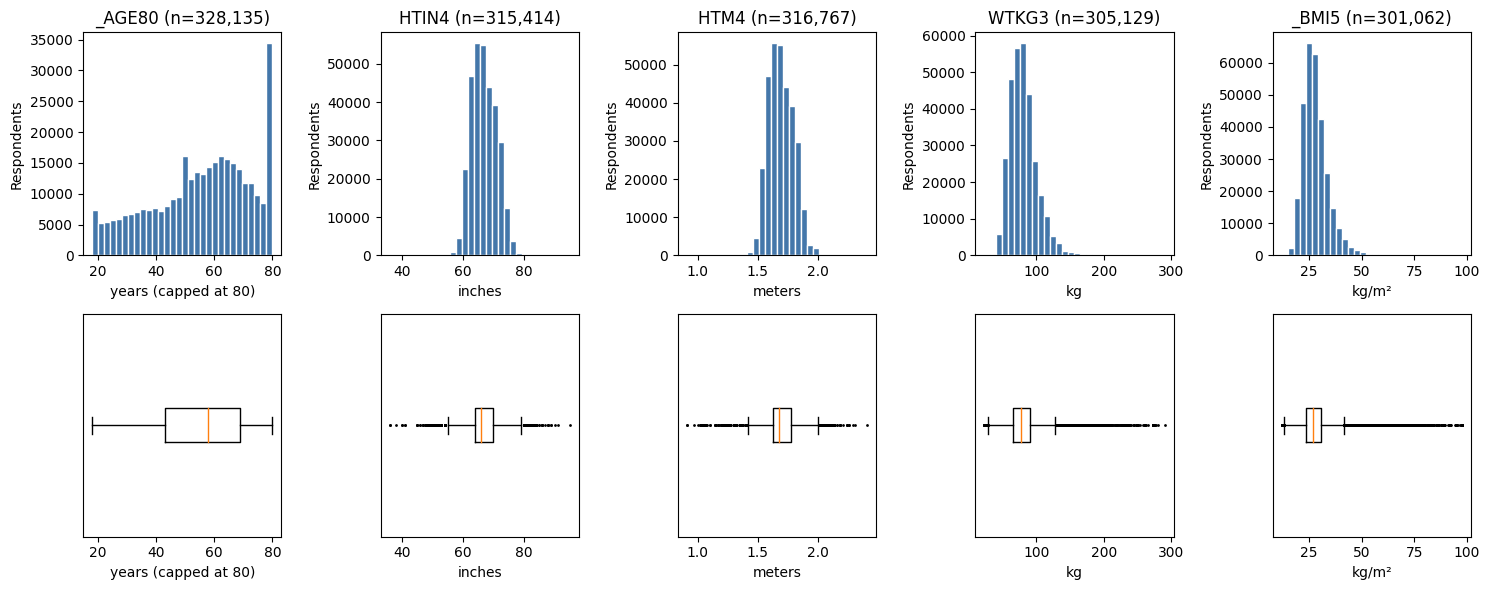

In [ ]:
# Keep distributions and tails visible; do not clip or remove observations.
fig, axes = plt.subplots(2, len(numeric_names), figsize=(15, 6))
for i, name in enumerate(numeric_names):
    observed = numeric_values[:, i]
    observed = observed[np.isfinite(observed)]
    axes[0, i].hist(observed, bins=30, color="#4477AA", edgecolor="white")
    axes[0, i].set_title(f"{name} (n={observed.size:,})")
    axes[0, i].set_ylabel("Respondents")
    axes[1, i].boxplot(observed, vert=False, whis=1.5,
                       flierprops={"marker": ".", "markersize": 2})
    axes[1, i].set_yticks([])
    for ax in axes[:, i]:
        ax.set_xlabel(numeric_units[i])
fig.tight_layout()
plt.show()


### How to interpret the output

Compare mean with median, inspect spread and tails, and read the observed counts beside the distributions. A long tail or an IQR flag can reflect real variation, subgroup differences, or a data-quality issue; the plot alone cannot distinguish them.

Age is capped at 80 in this supplied feature, so any pile-up at 80 reflects that representation. Do not interpret the cap as a natural upper age limit. Height in inches and meters should show similar shapes, but they have different observed coverage and rounding. BMI is derived from weight and height, so the three distributions are related.

Box-plot whiskers end at observed values within the IQR bounds; they need not equal the printed bounds exactly. Points beyond them are inspection candidates, not automatic deletion candidates. If IQR is zero, the box plot still shows the observed data, while our summary deliberately withholds IQR flags.

**Decision:** describe and flag only. Do not drop respondents, clip values, impute, or change raw columns based on these plots. Any proposed transformation needs a rationale and local validation.

### Findings from the full-data run

- Mean height is **1.69 m**, mean weight **80.91 kg**, and mean BMI **28.03 kg/m²**. The course CSV already uses these units.
- Weight's mean (**80.91 kg**) exceeds its median (**77.56 kg**), as does BMI's mean (**28.03**) versus median (**26.93**). This is consistent with larger values pulling the means upward; inspect the distributions rather than assuming symmetric measurements.
- The IQR rule flags **7,967 weight observations (2.61% of observed weights)** and **10,196 BMI observations (3.39% of observed BMIs)**. These are feature-wise counts and must not be added as if they represented distinct respondents.
- Height flags are less frequent: **648 (0.21%)** for inches and **1,087 (0.34%)** for meters. The units, rounding, coverage, and resulting quartiles differ; flags need not identify identical sets of respondents.
- No age values fall outside the IQR bounds. This does not establish error-free ages: the feature is already imputed and capped at 80.
- Extreme values, such as maximum weight **289.85 kg** and BMI **97.65**, are inspection candidates. These summaries alone do not establish that they are invalid.

**Conclusion:** there are tails worth investigating, especially for weight and BMI, but no evidence here justifies automatically deleting or clipping respondents. Keep the data intact and compare any proposed treatment through local validation.


## 7. Duplicate-row checks

**Question:** are any recorded feature rows repeated?

Keep the original notebook's `np.unique(..., axis=0)` approach, with one correction: treat NaNs in matching positions as equal. We replace them with a marker only in a temporary comparison copy. The supplied feature values must contain no infinities so that the marker cannot collide with an observed value.

First compare all raw features, then optionally repeat without `SEQNO` and `_PSU`. Other metadata still participates. The separate CSV row ID is already outside the feature matrix.

This counts exact recorded patterns, not unique people. No rows are removed. It may take time and extra memory to sort the full matrix.


In [ ]:
def count_duplicate_rows(X):
    """Count repeated rows, treating NaNs in matching positions as equal."""
    # Infinity is reserved as the missing-value marker in the comparison copy.
    assert not np.isinf(X).any(), "Cannot use infinity as a marker: X already contains it."
    comparison = np.where(np.isnan(X), np.inf, X)
    unique_rows = np.unique(comparison, axis=0)
    return X.shape[0] - unique_rows.shape[0]


n_duplicates = count_duplicate_rows(X_train_raw)
print("Duplicate rows (all raw features):", n_duplicates)


Duplicate rows (all raw features): 0


In [ ]:
# Optional: check whether sequence fields are hiding repeated feature patterns.
columns = [i for i, name in enumerate(feature_names) if name not in {"SEQNO", "_PSU"}]
n_duplicates_without_sequence = count_duplicate_rows(X_train_raw[:, columns])
print("Duplicate rows (without SEQNO and _PSU):", n_duplicates_without_sequence)


Duplicate rows (without SEQNO and _PSU): 0


### Conclusion

The simplified full-data check found **zero exact duplicate rows**, both with all features and without the two sequence fields. Keep all rows.

Zero exact duplicates does not rule out repeated individuals, similar profiles, or duplicates after further preprocessing.

**Next: section 8 — identifying categorical features.**


## 8. Identifying categorical features

**Question:** which columns might contain categories rather than numerical measurements?

The original notebook lists features with **1 to 10 distinct observed values**, ignoring NaNs. We keep the same screen and add observed counts. The list is a starting point for checking response meanings, not an automatic feature-type assignment.

**Few distinct values does not mean unordered categories:**

| Example | What the values mean | What that tells us |
| --- | --- | --- |
| `GENHLTH` | Codes 1–5 describe progressively worse general health; 7 is unknown and 9 is refused. [Codebook p. 13](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=13) | The health responses are ordered categories. Codes 7 and 9 are not worse health levels. |
| `IYEAR` | Interview year. [Codebook p. 6](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=6) | Two observed years do not make the field an unordered category. |
| `_STATE` | State/territory identifier. [Codebook pp. 2–3](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=2) | Categories have no numerical ordering, even though there are more than 10. The screen misses this example. |

A column with only one observed value also enters the screen; section 3 already identifies those. Special response codes may inflate the number of distinct recorded values. Meanings must be checked column by column.

This section uses labeled features without targets or the benchmark. It does not encode categories or choose model inputs.


In [ ]:
# Reuse section 3's distinct counts; apply the teammate's exact 1–10 rule.
low_cardinality_columns = np.flatnonzero((distinct_counts >= 1) & (distinct_counts <= 10))
print(f"Columns with 1–10 distinct observed values: {low_cardinality_columns.size} of {n_features}")
print(f"{'Feature':<16} {'Distinct':>9} {'Observed':>10}  Raw observed values")
for i in low_cardinality_columns:
    column = X_train_raw[:, i]
    values = np.unique(column[~np.isnan(column)])
    print(f"{feature_names[i]:<16} {values.size:>9} {observed_counts[i]:>10,}  {values}")


Columns with 1–10 distinct observed values: 219 of 321
Feature           Distinct   Observed  Raw observed values
IYEAR                    2    328,135  [2015. 2016.]
DISPCODE                 2    328,135  [1100. 1200.]
CTELENUM                 1    188,720  [1.]
PVTRESD1                 2    188,720  [1. 2.]
COLGHOUS                 1         32  [1.]
STATERES                 1    188,719  [1.]
CELLFON3                 2    188,720  [1. 2.]
LADULT                   2         32  [1. 2.]
CTELNUM1                 1    139,415  [1.]
CELLFON2                 1    139,415  [1.]
CADULT                   2    139,414  [1. 2.]
PVTRESD2                 2    139,415  [1. 2.]
CCLGHOUS                 1        801  [1.]
CSTATE                   2    139,416  [1. 2.]
LANDLINE                 4    138,848  [1. 2. 7. 9.]
GENHLTH                  7    328,133  [1. 2. 3. 4. 5. 7. 9.]
HLTHPLN1                 4    328,135  [1. 2. 7. 9.]
PERSDOC2                 5    328,135  [1. 2. 3. 7. 9.]
MEDCOST   

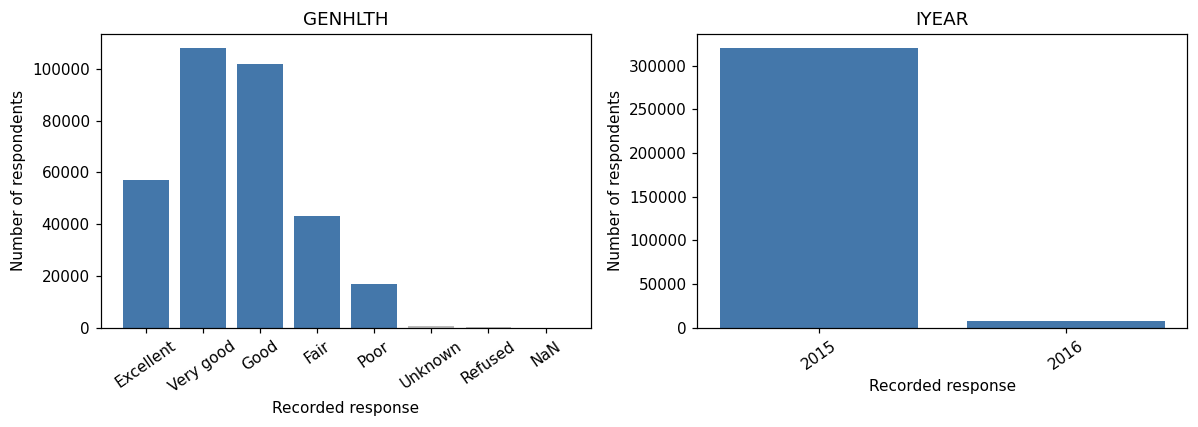

In [ ]:
# Two examples: ordered responses vs. numerical years. Labels are for display only.
health_labels = {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor",
                 7: "Unknown", 9: "Refused"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["GENHLTH", "IYEAR"]):
    column = X_train_raw[:, feature_names.index(name)]
    values, counts = np.unique(column[~np.isnan(column)], return_counts=True)
    labels = [health_labels[value] if name == "GENHLTH" else f"{value:g}" for value in values]
    colors = ["#BBBBBB" if name == "GENHLTH" and value in (7, 9) else "#4477AA" for value in values]
    # Show raw NaNs separately when present; do not silently drop them from the plot.
    if np.isnan(column).any():
        labels.append("NaN")
        counts = np.append(counts, np.isnan(column).sum())
        colors.append("#BBBBBB")
    ax.bar(labels, counts, color=colors)
    ax.set(title=name, xlabel="Recorded response", ylabel="Number of respondents")
    ax.tick_params(axis="x", labelrotation=35)
fig.tight_layout()
plt.show()


### What can we say?

The printed list identifies **low-cardinality columns**, not a confirmed list of unordered categorical features. Use the codebook to distinguish ordered responses, unordered categories, counts, dates, and special codes.

The plots show how responses are distributed. `GENHLTH`'s unknown/refused bars represent recorded answers that are not health levels, even though they are not NaNs. `IYEAR` illustrates why counting unique values alone cannot establish a variable's type.

**Decision:** keep all features and raw codes unchanged. Check meanings before choosing category encoding; fit any learned encoding on the local training portion.

**Next: section 9 — target class distribution.**


## 9. Target class distribution

**Question:** how many examples belong to each target class?

Like the original notebook, count the `-1` and `1` labels and plot their frequencies. We also show the accuracy obtained by always predicting the majority class, to explain why accuracy alone can be misleading. Here, **1 is the positive class**.

This describes the overall balance of the supplied labeled data. It is not a held-out model evaluation. For an evaluated baseline, choose the majority class from the local training split and score predictions on the appropriate validation/test split.


In [ ]:
# Same class-count calculation as the original notebook.
classes, class_counts = np.unique(y_raw, return_counts=True)
class_percentages = 100 * class_counts / y_raw.size
print(f"{'Class':>7} {'Examples':>12} {'Share':>10}")
for label, count, percentage in zip(classes, class_counts, class_percentages):
    print(f"{label:>7} {count:>12,} {percentage:>9.2f}%")

majority_class = classes[np.argmax(class_counts)]
majority_accuracy = class_counts.max() / y_raw.size
print(f"\nAlways predicting {majority_class}: {majority_accuracy:.2%} accuracy on these labels.")
if majority_class == -1:
    print("This predicts no positive cases: positive-class recall and F1 are both 0.")


  Class     Examples      Share
     -1      299,160     91.17%
      1       28,975      8.83%

Always predicting -1: 91.17% accuracy on these labels.
This predicts no positive cases: positive-class recall and F1 are both 0.


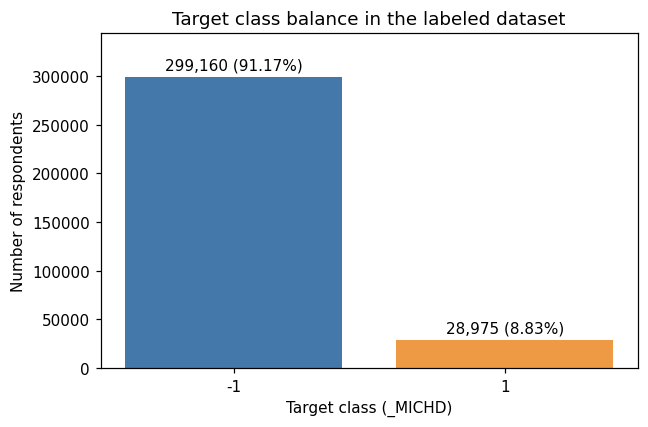

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([str(label) for label in classes], class_counts, color=["#4477AA", "#EE9944"])
for bar, count, percentage in zip(bars, class_counts, class_percentages):
    ax.annotate(f"{count:,} ({percentage:.2f}%)",
                (bar.get_x() + bar.get_width() / 2, count),
                xytext=(0, 5), textcoords="offset points", ha="center")
ax.set(xlabel="Target class (_MICHD)", ylabel="Number of respondents",
       title="Target class balance in the labeled dataset", ylim=(0, class_counts.max() * 1.15))
fig.tight_layout()
plt.show()


### What can we conclude?

- **299,160 negatives (91.17%)** and **28,975 positives (8.83%)**: the target classes are imbalanced.
- Predicting `-1` for everyone gives **91.17% accuracy**, but identifies none of the positive cases. High accuracy alone therefore does not demonstrate a useful classifier.
- Use reproducible, stratified local splits so each split retains approximately the same class balance. Alongside accuracy, report a confusion matrix and positive-class precision, recall, and F1; confirm the competition metric before selecting a model.
- Class weighting, resampling, and threshold changes are possible experiments, not decisions established by this count. Any resampling belongs within the training portion; threshold selection belongs on local validation data.

No rows or labels are changed. The next section describes feature–target associations across all labeled data, as in the original notebook, and notes the implications for later splitting and feature selection.

**Next: section 10 — associations between features and the target.**


## 10. Associations between features and the target

**Question:** do the target proportions differ across a feature's recorded categories?

The original notebook ranks all features using **Cramér's V**, including continuous measurements and near-unique weights. Treating every numerical value as a category can inflate that score. We keep the same calculation, but screen **2–10 distinct observed values in the labeled data**, skip the known numerical year field `IYEAR`, and show observed support.

This is a first pass over categorical candidates, not a complete analysis of all features. As section 8 explains, the distinct-value rule alone does not confirm a feature's type. Constant fields, continuous measurements, and categories with more than 10 values are outside this screen.

**Note for later modeling:** like the original notebook, this is descriptive analysis of all supplied labeled rows. A ranking can change with the rows included in a split. If we use it to choose features, labels used here have already influenced that choice; a later split from the same data cannot be described as a fully untouched test set. For independent evaluation, repeat feature-selection steps on training data only using the future `src` split. No split is created in this notebook.


### What does Cramér's V measure?

It compares a category-by-target count table with the counts expected if the two were independent. The formula is `V = sqrt(chi² / (n × min(number_of_categories − 1, number_of_target_classes − 1)))`.

Values near **0** indicate little association in that table; larger values indicate stronger association, up to **1**. V does not give a positive/negative direction, establish causation, or measure a trained model's predictive performance.

Require at least **1,000 observed rows and 1% of all labeled rows**, following the support check in section 5. This is a screening setting, not a statistical significance test. Recorded unknown/refused codes still count as categories for now; section 11 will investigate special codes before we revisit these results.


In [ ]:
def cramers_v(x, y):
    """Association between recorded categories and a target, ignoring NaNs."""
    valid = ~np.isnan(x) & ~np.isnan(y)
    x, y = x[valid], y[valid]
    categories, x_codes = np.unique(x, return_inverse=True)
    classes, y_codes = np.unique(y, return_inverse=True)
    if categories.size < 2 or classes.size < 2:
        return np.nan
    table = np.zeros((categories.size, classes.size), dtype=int)
    np.add.at(table, (x_codes, y_codes), 1)
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / table.sum()
    chi_squared = np.sum((table - expected) ** 2 / expected)
    return np.sqrt(chi_squared / (table.sum() * min(table.shape[0] - 1, table.shape[1] - 1)))


# Descriptive ranking on all labeled rows; no split is created or required here.
min_association_rows = max(1000, int(np.ceil(0.01 * y_raw.size)))
association_results = []
for i, name in enumerate(feature_names):
    if name == "IYEAR":
        continue  # A numerical year, not a categorical candidate for this screen.
    x = X_train_raw[:, i]
    observed = ~np.isnan(x)
    n_observed = int(observed.sum())
    n_categories = np.unique(x[observed]).size
    if 2 <= n_categories <= 10 and n_observed >= min_association_rows:
        score = cramers_v(x, y_raw)
        if np.isfinite(score):
            association_results.append((name, score, n_observed, n_categories))

association_results.sort(key=lambda row: row[1], reverse=True)
print(f"Ranked {len(association_results)} candidates; minimum observed rows: {min_association_rows:,}")
print(f"{'Feature':<16} {'Cramér V':>10} {'Observed':>10} {'Labeled coverage':>17} {'Categories':>11}")
for name, score, count, n_categories in association_results:
    print(f"{name:<16} {score:>10.4f} {count:>10,} {count / y_raw.size:>17.2%} {n_categories:>11}")


Ranked 188 candidates; minimum observed rows: 3,282
Feature            Cramér V   Observed  Labeled coverage  Categories
GENHLTH              0.2664    328,133           100.00%           7
CVDASPRN             0.2572     14,046             4.28%           4
_RFHLTH              0.2352    328,135           100.00%           3
EMPLOY1              0.2314    328,135           100.00%           9
_AGE_G               0.2221    328,135           100.00%           6
BPHIGH4              0.2176    328,134           100.00%           6
_RFHYPE5             0.2172    328,135           100.00%           3
DIFFWALK             0.2160    318,986            97.21%           4
DRADVISE             0.2102     30,592             9.32%           4
CVDSTRK3             0.2095    328,135           100.00%           4
_AGE65YR             0.2032    328,135           100.00%           3
_HCVU651             0.1973    328,135           100.00%           3
USEEQUIP             0.1927    320,392            9

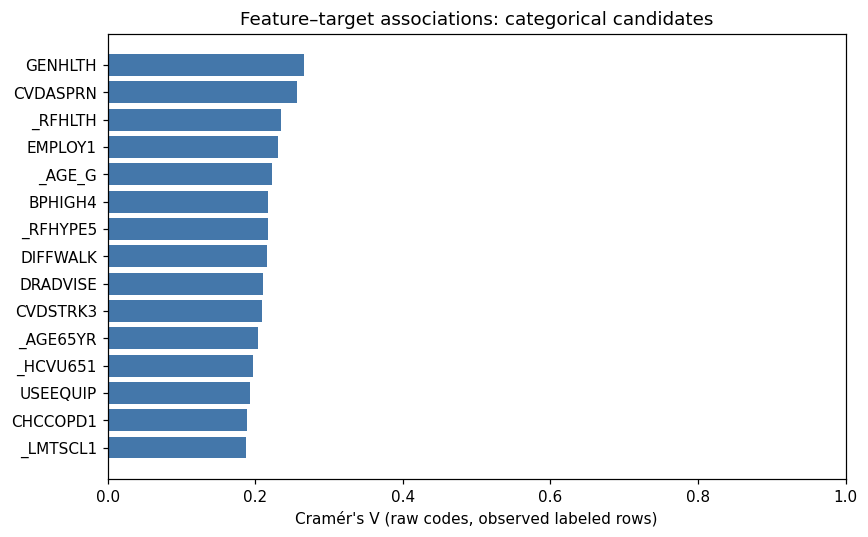

In [ ]:
# Show the leading 15 candidates; support counts remain in the table above.
top_associations = association_results[:15]
if top_associations:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh([row[0] for row in top_associations], [row[1] for row in top_associations], color="#4477AA")
    ax.invert_yaxis()
    ax.set(xlim=(0, 1), xlabel="Cramér's V (raw codes, observed labeled rows)",
           title="Feature–target associations: categorical candidates")
    fig.tight_layout()
    plt.show()
else:
    print("No candidates meet this screen's category and support requirements.")


### What can we conclude?

Higher-ranked candidates have stronger associations with the target in their observed labeled subsets. A low score is not proof that a feature is useless: interactions and alternative representations can matter. The ranking is not a model feature-importance ranking.

Read support alongside each score. Different features are evaluated on different observed subsets; small categories and the number of categories can also affect this uncorrected V estimate. The support threshold does not eliminate those concerns. A relationship may reflect recorded unknown/refused codes or survey routing rather than the intended response itself.

**Decision:** use this ranking to guide investigation, not automatic feature selection. Verify meanings and special codes, then test proposed changes on local validation data. No feature selection is applied here, and the competition benchmark is not used. See the note above before using these exploratory results to guide modeling.

**Next: section 11 — special survey response codes.**


## 11. Special survey response codes

**Question:** do some recorded numbers stand for a survey response rather than a measurement?

Like the original notebook, scan for `[9, 77, 88, 99, 777, 9999, 99900]` and display matches accounting for at least **1% of a column's observed values**. We also show the percentage of **all labeled rows**, so a frequent code in a sparse column is not mistaken for a frequent response overall.

**A matching number is not automatically a missing value.** Definitions are specific to each field:

| Field and code | Meaning | What that suggests, before any model comparison |
| --- | --- | --- |
| `PHYSHLTH = 88` | Zero days of poor physical health. [Codebook p. 13](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=13) | Could represent as zero days, not missing. |
| `PHYSHLTH = 77` or `99` | Unknown or refused response, respectively. [p. 13](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=13) | Candidates for explicit missing-response handling. |
| `GENHLTH = 9` | Refused response. [p. 13](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=13) | Not a health level above 5. |
| `_DUALUSE = 9` | No dual phone use. [p. 103](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=103) | A legitimate category; keep its meaning. |
| `_STATE = 9` | Connecticut. [p. 2](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=2) | A legitimate geographic category. |

The list is a search aid, not a complete dictionary. For example, `GENHLTH = 7` is also an unknown response but is absent from the teammate's search list. A rare code below 1% can still need handling. Check the actual course CSV too: section 5 showed that some original survey encodings are already converted.

We inspect all labeled feature rows, without targets or the competition benchmark. No codes are replaced in this section.


In [ ]:
# Same candidate codes and display threshold as the original notebook.
suspected_codes = [9, 77, 88, 99, 777, 9999, 99900]
code_display_threshold = 1.0
code_matches = []
for i, name in enumerate(feature_names):
    column = X_train_raw[:, i]
    observed = column[~np.isnan(column)]
    if observed.size == 0:
        continue
    for code_value in suspected_codes:
        count = int(np.count_nonzero(observed == code_value))
        if count:
            code_matches.append((name, code_value, count, observed.size,
                                 100 * count / observed.size, 100 * count / X_train_raw.shape[0]))

code_matches.sort(key=lambda row: row[4], reverse=True)
flagged_codes = [row for row in code_matches if row[4] >= code_display_threshold]
print(f"Feature/code matches at or above {code_display_threshold:g}% of observed responses: {len(flagged_codes)}")
print(f"{'Feature':<16} {'Code':>8} {'Count':>10} {'Observed':>10} {'% observed':>12} {'% all rows':>12}")
for name, code_value, count, observed_count, pct_observed, pct_all in flagged_codes:
    print(f"{name:<16} {code_value:>8} {count:>10,} {observed_count:>10,} "
          f"{pct_observed:>12.2f} {pct_all:>12.2f}")


Feature/code matches at or above 1% of observed responses: 115
Feature              Code      Count   Observed   % observed   % all rows
ADMOVE                 88     13,126     15,080        87.04         4.00
ADTHINK                88     12,719     15,091        84.28         3.88
ADFAIL                 88     12,362     15,103        81.85         3.77
_CHISPNC                9    191,518    237,699        80.57        58.37
DRNK3GE5               88    117,010    156,923        74.57        35.66
ADDOWN                 88     11,102     15,128        73.39         3.38
CHILDREN               88    240,617    328,132        73.33        73.33
MENTHLTH               88    224,183    328,135        68.32        68.32
ADPLEASR               88     10,168     15,141        67.16         3.10
ASERVIST               88        150        228        65.79         0.05
ADEAT1                 88      9,684     15,108        64.10         2.95
PHYSHLTH               88    204,264    328,134  

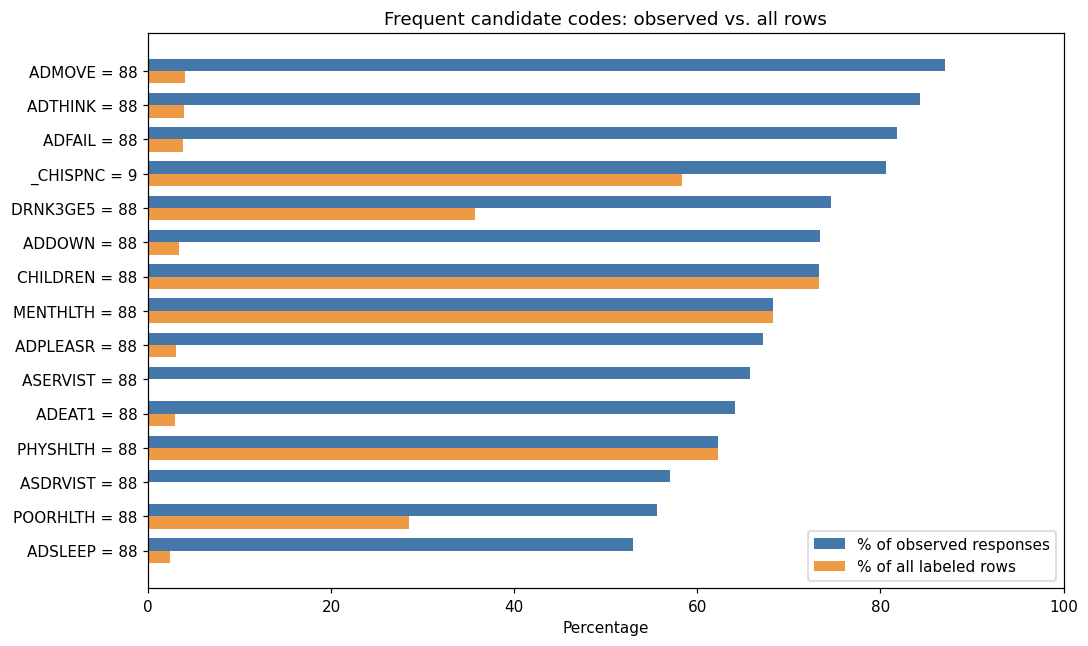

In [ ]:
# Compare denominators for the leading 15 matches. These are not all missing codes.
top_codes = flagged_codes[:15]
if top_codes:
    positions = np.arange(len(top_codes))
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(positions - 0.18, [row[4] for row in top_codes], height=0.36,
            label="% of observed responses", color="#4477AA")
    ax.barh(positions + 0.18, [row[5] for row in top_codes], height=0.36,
            label="% of all labeled rows", color="#EE9944")
    ax.set_yticks(positions)
    ax.set_yticklabels([f"{row[0]} = {row[1]}" for row in top_codes])
    ax.invert_yaxis()
    ax.set(xlim=(0, 100), xlabel="Percentage", title="Frequent candidate codes: observed vs. all rows")
    ax.legend()
    fig.tight_layout()
    plt.show()
else:
    print("No matches meet the display threshold.")


### What can we conclude?

Frequent candidate codes deserve interpretation, not automatic replacement. The same number can represent zero, an unknown/refused response, or a legitimate category depending on the field. Do not globally turn 9, 77, or 88 into NaN.

A large gap between the two bars means a code is frequent within a small observed subset. This connects the results to section 4: low raw-NaN rates do not guarantee complete information, and high code frequencies do not necessarily describe many respondents overall.

### Findings from this run

- **115 feature/code matches** meet the display threshold. This is not a count of missing-value codes or distinct features: a field can have several matches, and legitimate values also match.
- `ADMOVE = 88` appears in **87.04% of observed responses**, but only **4.00% of all labeled rows**. The denominator changes the interpretation substantially.

**Decision:** keep the raw arrays unchanged. Use the codebook to build field-specific mappings later; distinguish zero from missing and account for converted CSV representations. Recompute relevant summaries after recoding. Any learned imputation or feature-selection policy belongs in the later training workflow, as noted in section 10.

**Next: section 12 — reviewing the proposed feature-removal list.**


## 12. Review the proposed feature-removal list

**Question:** do the reasons given for the original removal list match the evidence so far?

The original notebook combines metadata, near-constant, missingness, and correlation decisions into one list, then deletes matching columns from `x_train`. Its saved output goes from **321 to 168 features**. Names absent from the header are silently ignored.

We copy the same list below, preserving its original group labels, **only to audit it**. We do not delete columns or treat the list as a confirmed preprocessing policy.

| Original reason | What needs checking? |
| --- | --- |
| Identifiers | Sequence numbers and geography are different kinds of information; `_STATE` is a category, not a respondent ID. See section 2. |
| Weight variables | `_DUALUSE` is a phone-use category, not a weight. Exclusion still needs a modeling rationale. |
| Child / unrelated demographics | Meaning alone does not establish whether a feature helps prediction. |
| Near-constant values | Section 3 supports the observed-value screen, but missingness and rare responses may still matter. |
| Missing values above 99% | The original earlier screen used **90%**, while this list's comment says **99%**. Check which rule the list actually meets. |
| Highly correlated | Only some examples have been verified in our smaller numerical review. A high correlation does not choose which representation to keep. |

These are hypotheses for later comparisons. Any learned selection belongs within training; applying a final selection must preserve the same feature order for validation, local test, and the competition benchmark. The original cell only changes `x_train`, so it is not yet a reusable train/benchmark transformation.


In [ ]:
# Copy of the teammate's list, grouped by their original comments. Review only.
original_removal_groups = {
    'Identifiers': (
        '_STATE FMONTH IDATE IMONTH IDAY IYEAR DISPCODE SEQNO _PSU'
    ).split(),
    'Weight variables': (
        '_WT2RAKE _STSTR _STRWT _RAWRAKE _DUALCOR _LLCPWT _CLLCPWT _DUALUSE'
    ).split(),
    'Child Demographics': (
        '_CRACE1 _CPRACE _CHISPNC'
    ).split(),
    'Near constant values': (
        'CTELENUM CTELNUM1 CELLFON2 PVTRESD1 COLGHOUS STATERES PVTRESD2 CCLGHOUS _FRT16 '
        '_VEG23'
    ).split(),
    'Unrelated Demographic variables': (
        'NUMHHOL2 CPDEMO1 NUMPHON2'
    ).split(),
    'Missing values superior to 99%': (
        'LADULT INSULIN BLDSUGAR FEETCHK2 DOCTDIAB CHKHEMO3 FEETCHK EYEEXAM DIABEYE DIABEDU '
        'CRGVREL1 CRGVLNG1 CRGVHRS1 CRGVPRB1 CRGVPERS CRGVHOUS CRGVMST2 VIDFCLT2 VIREDIF3 '
        'VIPRFVS2 VINOCRE2 VIEYEXM2 VIINSUR2 VICTRCT4 VIGLUMA2 VIMACDG2 CDHOUSE CDASSIST '
        'CDHELP CDSOCIAL CDDISCUS WTCHSALT LONGWTCH DRADVISE ASTHMAGE ASATTACK ASERVIST '
        'ASDRVIST ASRCHKUP ASACTLIM ASYMPTOM ASNOSLEP ASTHMED3 ASINHALR HAREHAB1 STREHAB1 '
        'CVDASPRN ASPUNSAF RLIVPAIN RDUCHART RDUCSTRK ARTTODAY ARTHWGT ARTHEXER ARTHEDU '
        'TETANUS HPVADVC2 HPVADSHT SHINGLE2 HADMAM HOWLONG HADPAP2 LASTPAP2 HPVTEST '
        'HPLSTTST HADHYST2 PROFEXAM LENGEXAM LSTBLDS3 HADSGCO1 LASTSIG3 PCPSAAD2 PCPSADI1 '
        'PCPSARE1 PSATEST1 PSATIME PCPSARS1 PCPSADE1 PCDMDECN SCNTPAID SCNTWRK1 SCNTLPAD '
        'SCNTLWK1 CASTHNO2 EMTSUPRT LSATISFY ADPLEASR ADDOWN ADSLEEP ADENERGY ADEAT1 ADFAIL '
        'ADTHINK ADMOVE MISTMNT ADANXEV'
    ).split(),
    'Highly correlated with other variables': (
        '_DRDXAR1 HTM4 SMOKDAY2 _PRACE1 MAXVO2_ _VEGETEX PADUR2_ PADUR1_ _FRUITEX _TOTINDA '
        '_DRNKWEK _RFSEAT3 ASTHNOW _LMTSCL1 _LMACT1 _AIDTST3 _LMTWRK1 SEX _PAINDX1 _PA30021 '
        '_EDUCAG _FRTLT1 _AGE80 _RACEGR3 _AGE_G'
    ).split(),
}

original_proposal = [name for names in original_removal_groups.values() for name in names]
proposed_present = [name for name in original_proposal if name in feature_names]
proposed_absent = [name for name in original_proposal if name not in feature_names]
print(f"{'Original reason':<39} {'Listed':>8} {'Found':>8}")
for group, names in original_removal_groups.items():
    print(f"{group:<39} {len(names):>8} {sum(name in feature_names for name in names):>8}")
print("\nNames not found:", proposed_absent)
print(f"If applied: {len(feature_names)} -> {len(feature_names) - len(proposed_present)} features.")
print("Review only: all raw features remain unchanged.")


Original reason                           Listed    Found
Identifiers                                    9        9
Weight variables                               8        8
Child Demographics                             3        3
Near constant values                          10       10
Unrelated Demographic variables                3        3
Missing values superior to 99%                96       96
Highly correlated with other variables        25       24

Names not found: ['_LMACT1']
If applied: 321 -> 168 features.
Review only: all raw features remain unchanged.


In [ ]:
# Check the original group labels against the descriptive statistics already computed.
near_constant_names = original_removal_groups["Near constant values"]
not_near_constant = [name for name in near_constant_names
                     if dominant_shares[feature_names.index(name)] < dominance_threshold]
print("Near-constant list entries failing the 99% observed-value screen:", not_near_constant)

missing_names = original_removal_groups["Missing values superior to 99%"]
not_above_99 = [name for name in missing_names if missing_pct[feature_names.index(name)] <= 99]
print(f"Missingness group: {len(not_above_99)} of {len(missing_names)} entries are NOT above 99% missing.")
print("Examples (up to 10):")
for name in not_above_99[:10]:
    i = feature_names.index(name)
    print(f"  {name:<14} {missing_pct[i]:.2f}% missing; {observed_counts[i]:,} observed rows")
print("Possible spelling mismatch: _LMACT1 is absent; _LMTACT1 exists:", "_LMTACT1" in feature_names)


Near-constant list entries failing the 99% observed-value screen: []
Missingness group: 68 of 96 entries are NOT above 99% missing.
Examples (up to 10):
  INSULIN        93.38% missing; 21,710 observed rows
  BLDSUGAR       93.38% missing; 21,709 observed rows
  FEETCHK2       93.38% missing; 21,707 observed rows
  DOCTDIAB       93.39% missing; 21,706 observed rows
  CHKHEMO3       93.39% missing; 21,706 observed rows
  FEETCHK        93.45% missing; 21,506 observed rows
  EYEEXAM        93.39% missing; 21,706 observed rows
  DIABEYE        93.39% missing; 21,705 observed rows
  DIABEDU        93.39% missing; 21,705 observed rows
  CRGVREL1       94.57% missing; 17,833 observed rows
Possible spelling mismatch: _LMACT1 is absent; _LMTACT1 exists: True


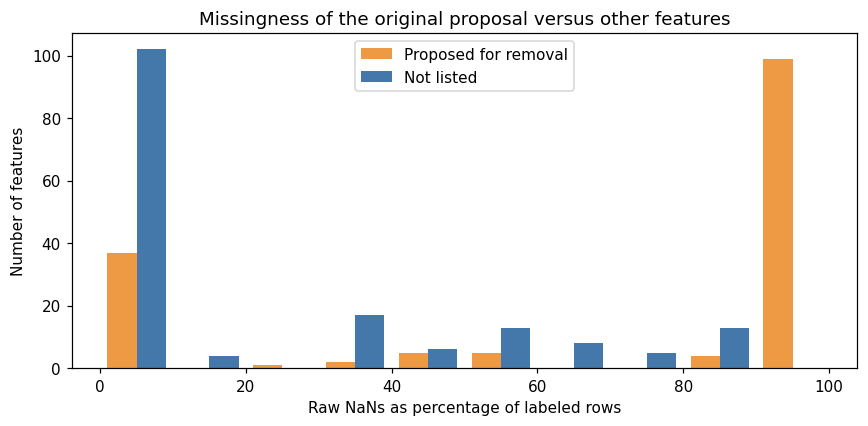

In [ ]:
# Compare raw missingness of proposed exclusions with the other columns.
# These labels describe the proposal; no feature selection is applied.
proposal_indices = [feature_names.index(name) for name in proposed_present]
other_indices = [i for i, name in enumerate(feature_names) if name not in proposed_present]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist([missing_pct[proposal_indices], missing_pct[other_indices]],
        bins=np.linspace(0, 100, 11), label=["Proposed for removal", "Not listed"],
        color=["#EE9944", "#4477AA"])
ax.set(xlabel="Raw NaNs as percentage of labeled rows", ylabel="Number of features",
       title="Missingness of the original proposal versus other features")
ax.legend()
fig.tight_layout()
plt.show()


### What can we conclude?

The proposal is substantial: **154 names are listed, 153 exist in the header, and applying it would leave 168 features**. The missing name `_LMACT1` is plausibly a typo for `_LMTACT1`, but we report that without silently changing the teammate's list.

**68 of the 96 entries** in the group labeled above 99% missing are actually at or below 99%. The missingness comment does not match the rule applied earlier, and several group labels combine fields with different meanings. The plot can show how much the list targets sparse columns; it cannot show whether removing those columns improves prediction.

**Decision:** keep every raw column. Resolve naming and rule inconsistencies, then compare proposed exclusions by reason using the same local validation settings. No array, feature order, or model input is changed here.

**Next: section 13 — field-specific response-code recoding.**


## 13. Field-specific response-code recoding

**Question:** how should documented zero/unknown/refused responses be represented?

The original notebook uses two dictionaries: **five fields** with codes changed to zero and **48 fields** with codes changed to NaN. It changes `x_train` directly. The field-specific approach is sensible, but the rules need checking: for example, several fields map 77 to missing while leaving the refused code 99 as a numerical value.

We keep the original dictionaries as a reference, then demonstrate a checked subset of **eight fields in a separate copy**. This is not a complete recoding specification for all 321 features, nor a production preprocessing pipeline.

| Reviewed fields | Zero codes | Missing codes | Source |
| --- | --- | --- | --- |
| `PHYSHLTH`, `MENTHLTH` | 88 means zero days. | 77 unknown; 99 refused. | [Codebook p. 13](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=13) |
| `POORHLTH` | 88 means zero days. | 77 unknown; 99 refused. | [p. 14](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=14) |
| `CHILDREN` | 88 means no children. | 99 refused. | [p. 25](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=25) |
| `DRNK3GE5` | 88 means no occasions. | 77 unknown; 99 refused. | [p. 33](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=33) |
| `INCOME2` | None in this example. | 77 unknown; 99 refused. | [p. 26](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=26) |
| `GENHLTH` | None in this example. | 7 unknown; 9 refused. | [p. 13](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=13) |
| `FRUITJU1` | Not changed here. | 777 unknown; 999 refused. | [p. 34](https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf#page=34) |

The numerical examples in section 5 showed why we must also inspect the actual course CSV instead of blindly reapplying the original survey's scaling. Keep legitimate codes such as `_DUALUSE = 9` unchanged. Existing NaNs are not assumed to mean zero, even where survey routing might explain some of them.


In [ ]:
# Original dictionaries, copied unchanged for comparison; not applied to raw data.
original_zero_codes = {
    'CHILDREN': [88], 'MENTHLTH': [88], 'PHYSHLTH': [88],
    'DRNK3GE5': [88], 'POORHLTH': [88],
}

original_missing_codes = {
    '_INCOMG': [9], '_PNEUMO2': [9], '_PAREC1': [9],
    '_PASTAE1': [9], '_PACAT1': [9], '_PA300R2': [9],
    '_PA150R2': [9], '_FLSHOT6': [9], '_VEGLT1': [9],
    '_PASTRNG': [9], '_RFSEAT2': [9], '_RFBMI5': [9],
    '_RFDRHV5': [9], '_RFBING5': [9], 'PAMISS1_': [9],
    'DRNKANY5': [9], 'RCSGENDR': [9], 'RCSRLTN2': [9],
    'CASTHDX2': [9], '_SMOKER3': [9], '_RFSMOK3': [9],
    '_CHOLCHK': [9], '_HCVU651': [9], '_LMTACT1': [9],
    'SXORIENT': [9], '_RACE': [9], '_RACEG21': [9],
    'ARTHDIS2': [9], 'INCOME2': [77, 99], 'MAXDRNKS': [77],
    'AVEDRNK2': [77], 'PHYSHLTH': [77], 'MENTHLTH': [77],
    'POORHLTH': [77], 'DRNK3GE5': [77], 'WHRTST10': [77],
    'JOINPAIN': [77], 'FRUITJU1': [777], 'EXERHMM1': [777],
    'EXERHMM2': [777], 'FVBEANS': [777], 'VEGETAB1': [777],
    'FRUIT1': [777], 'FVORANG': [777], 'FVGREEN': [777],
    '_MRACE1': [99], 'WEIGHT2': [9999], 'HEIGHT3': [9999],
}

print(f"Original rules: {len(original_zero_codes)} fields with zero codes, "
      f"{len(original_missing_codes)} fields with missing codes.")
print("Rule names absent from the CSV:", [
    name for name in set(original_zero_codes) | set(original_missing_codes) if name not in feature_names
])


Original rules: 5 fields with zero codes, 48 fields with missing codes.
Rule names absent from the CSV: []


In [ ]:
# Reviewed example: keep the original five zero mappings; complete missing codes
# only for these eight documented fields. Raw arrays and feature names are untouched.
zero_codes = original_zero_codes
reviewed_missing_codes = {
    "CHILDREN": [99], "PHYSHLTH": [77, 99], "MENTHLTH": [77, 99],
    "POORHLTH": [77, 99], "DRNK3GE5": [77, 99], "INCOME2": [77, 99],
    "GENHLTH": [7, 9], "FRUITJU1": [777, 999],
}
recoding_names = list(reviewed_missing_codes)
raw_examples = X_train_raw[:, [feature_names.index(name) for name in recoding_names]].copy()
recoded_examples = raw_examples.copy()
print(f"{'Feature':<12} {'To zero':>10} {'New NaNs':>10} {'Missed before':>14} {'NaN % before':>14} {'NaN % after':>13}")
for i, name in enumerate(recoding_names):
    before = raw_examples[:, i]
    zero_mask = np.isin(before, zero_codes.get(name, []))
    missing_mask = np.isin(before, reviewed_missing_codes[name])
    recoded_examples[zero_mask, i] = 0
    recoded_examples[missing_mask, i] = np.nan
    # Count missing responses not covered by the teammate's original dictionary.
    additional = missing_mask & ~np.isin(before, original_missing_codes.get(name, []))
    print(f"{name:<12} {zero_mask.sum():>10,} {missing_mask.sum():>10,} {additional.sum():>14,} "
          f"{100 * np.isnan(before).mean():>14.2f} {100 * np.isnan(recoded_examples[:, i]).mean():>13.2f}")


Feature         To zero   New NaNs  Missed before   NaN % before   NaN % after
CHILDREN        240,617      2,724          2,724           0.00          0.83
PHYSHLTH        204,264      7,107          1,520           0.00          2.17
MENTHLTH        224,183      5,359          1,598           0.00          1.63
POORHLTH         93,548      3,557            887          48.72         49.80
DRNK3GE5        117,010      2,202            472          52.18         52.85
INCOME2               0     56,123              0           0.75         17.86
GENHLTH               0        886            886           0.00          0.27
FRUITJU1              0      7,628          1,686           6.32          8.64


PHYSHLTH raw-code mean (not a mean in days): 60.72
PHYSHLTH mean days after reviewed recoding: 4.27


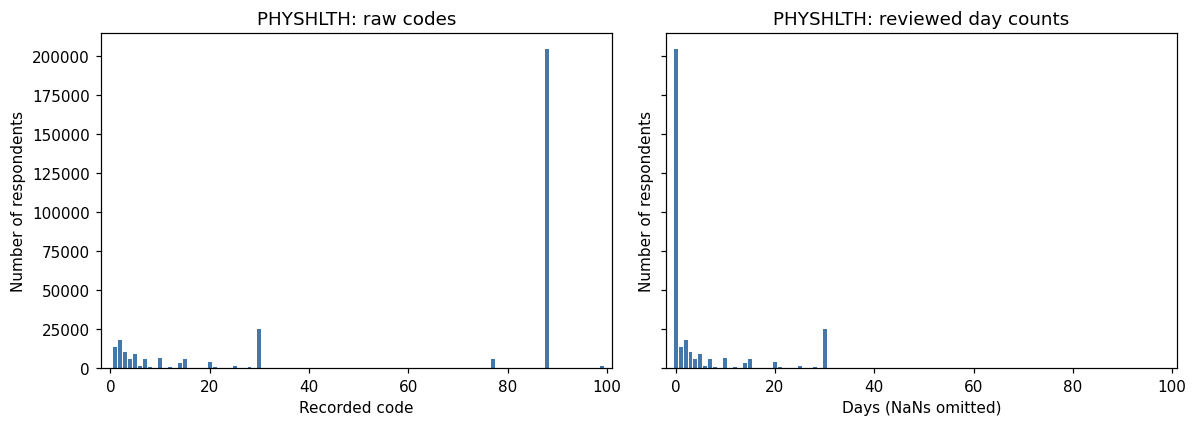

In [ ]:
# Example: the raw code 88 becomes zero days; 77 and 99 become NaN.
i = recoding_names.index("PHYSHLTH")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, values, title in zip(axes, [raw_examples[:, i], recoded_examples[:, i]],
                              ["PHYSHLTH: raw codes", "PHYSHLTH: reviewed day counts"]):
    observed = values[~np.isnan(values)]
    codes, counts = np.unique(observed, return_counts=True)
    ax.bar(codes, counts, color="#4477AA")
    ax.set(title=title, xlabel="Recorded code" if "raw" in title else "Days (NaNs omitted)",
           ylabel="Number of respondents", xlim=(-2, 101))
fig.tight_layout()
plt.show()

print("PHYSHLTH raw-code mean (not a mean in days):", round(np.nanmean(raw_examples[:, i]), 2))
print("PHYSHLTH mean days after reviewed recoding:", round(np.nanmean(recoded_examples[:, i]), 2))


### What can we conclude?

- The original zero mappings capture an important distinction: a recorded code for none can mean **zero**, whereas an absent, unknown, or refused response should not silently become zero.
- The before/after table shows responses omitted by the original missing-code rules. A larger NaN percentage here reflects recognizing unknown/refused answers already present as numbers, not creating new nonresponses.
- Raw-code means can be misleading. `PHYSHLTH = 88` must not be interpreted as 88 days in a 30-day question.
- These eight fields are examples. Other original mappings still need verification, and `FRUITJU1` still mixes daily, weekly, and monthly frequency encodings. Removing its missing codes alone does not make it a consistent numerical frequency.

In this run, the `PHYSHLTH` raw-code mean is **60.72**, while the reviewed mean among known day counts is **4.27 days**. These use different observed subsets after unknown/refused responses are excluded; the raw-code mean was never a valid day-count estimate.

**Decision:** keep `X_train_raw`, the benchmark, and all feature names unchanged. The demonstration changes only `recoded_examples`. Recompute distributions and associations after any adopted recoding, and define the same deterministic rules for every model input split. Imputation and other learned parameters belong in the later training workflow; there is no split or model training here.

This completes the 13-topic review of the original notebook. It documents observations and proposed improvements; it does not establish a final feature set or a fully cleaned dataset.
